# Perceptron : Une introduction au Deep Learning

In [16]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns 

from sklearn.preprocessing import RobustScaler

## Chargement des données

In [17]:
df = pd.read_csv('../data/bcw_data.csv')
df

,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,...,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst,Unnamed: 32
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.30010,0.14710,...,17.33,184.60,2019.0,0.16220,0.66560,0.7119,0.2654,0.4601,0.11890,NaN
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.08690,0.07017,...,23.41,158.80,1956.0,0.12380,0.18660,0.2416,0.1860,0.2750,0.08902,NaN
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.19740,0.12790,...,25.53,152.50,1709.0,0.14440,0.42450,0.4504,0.2430,0.3613,0.08758,NaN
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.24140,0.10520,...,26.50,98.87,567.7,0.20980,0.86630,0.6869,0.2575,0.6638,0.17300,NaN
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.19800,0.10430,...,16.67,152.20,1575.0,0.13740,0.20500,0.4000,0.1625,0.2364,0.07678,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
564,926424,M,21.56,22.39,142.00,1479.0,0.11100,0.11590,0.24390,0.13890,...,26.40,166.10,2027.0,0.14100,0.21130,0.4107,0.2216,0.2060,0.07115,NaN
565,926682,M,20.13,28.25,131.20,1261.0,0.09780,0.10340,0.14400,0.09791,...,38.25,155.00,1731.0,0.11660,0.19220,0.3215,0.1628,0.2572,0.06637,NaN
566,926954,M,16.60,28.08,108.30,858.1,0.08455,0.10230,0.09251,0.05302,...,34.12,126.70,1124.0,0.11390,0.30940,0.3403,0.1418,0.2218,0.07820,NaN
567,927241,M,20.60,29.33,140.10,1265.0,0.11780,0.27700,0.35140,0.15200,...,39.42,184.60,1821.0,0.16500,0.86810,0.9387,0.2650,0.4087,0.12400,NaN


## EDA

In [18]:
df.describe()

,id,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,...,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst,Unnamed: 32
count,5.690000e+02,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,...,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,0.0
mean,3.037183e+07,14.127292,19.289649,91.969033,654.889104,0.096360,0.104341,0.088799,0.048919,0.181162,...,25.677223,107.261213,880.583128,0.132369,0.254265,0.272188,0.114606,0.290076,0.083946,NaN
std,1.250206e+08,3.524049,4.301036,24.298981,351.914129,0.014064,0.052813,0.079720,0.038803,0.027414,...,6.146258,33.602542,569.356993,0.022832,0.157336,0.208624,0.065732,0.061867,0.018061,NaN
min,8.670000e+03,6.981000,9.710000,43.790000,143.500000,0.052630,0.019380,0.000000,0.000000,0.106000,...,12.020000,50.410000,185.200000,0.071170,0.027290,0.000000,0.000000,0.156500,0.055040,NaN
25%,8.692180e+05,11.700000,16.170000,75.170000,420.300000,0.086370,0.064920,0.029560,0.020310,0.161900,...,21.080000,84.110000,515.300000,0.116600,0.147200,0.114500,0.064930,0.250400,0.071460,NaN
50%,9.060240e+05,13.370000,18.840000,86.240000,551.100000,0.095870,0.092630,0.061540,0.033500,0.179200,...,25.410000,97.660000,686.500000,0.131300,0.211900,0.226700,0.099930,0.282200,0.080040,NaN
75%,8.813129e+06,15.780000,21.800000,104.100000,782.700000,0.105300,0.130400,0.130700,0.074000,0.195700,...,29.720000,125.400000,1084.000000,0.146000,0.339100,0.382900,0.161400,0.317900,0.092080,NaN
max,9.113205e+08,28.110000,39.280000,188.500000,2501.000000,0.163400,0.345400,0.426800,0.201200,0.304000,...,49.540000,251.200000,4254.000000,0.222600,1.058000,1.252000,0.291000,0.663800,0.207500,NaN


In [19]:
df .isna().sum()

id                           0
diagnosis                    0
radius_mean                  0
texture_mean                 0
perimeter_mean               0
area_mean                    0
smoothness_mean              0
compactness_mean             0
concavity_mean               0
concave points_mean          0
symmetry_mean                0
fractal_dimension_mean       0
radius_se                    0
texture_se                   0
perimeter_se                 0
area_se                      0
smoothness_se                0
compactness_se               0
concavity_se                 0
concave points_se            0
symmetry_se                  0
fractal_dimension_se         0
radius_worst                 0
texture_worst                0
perimeter_worst              0
area_worst                   0
smoothness_worst             0
compactness_worst            0
concavity_worst              0
concave points_worst         0
symmetry_worst               0
fractal_dimension_worst      0
Unnamed:

In [20]:
df.duplicated().sum()

np.int64(0)

In [21]:
df['id'].duplicated().sum()

np.int64(0)

<Axes: >

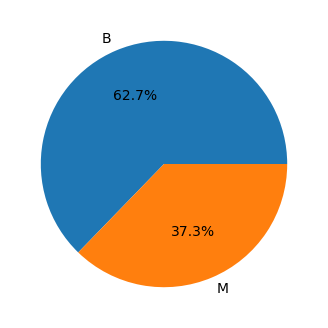

In [27]:
df['diagnosis'].value_counts().plot(kind='pie', figsize=(4, 4), autopct='%1.1f%%', ylabel='')

In [23]:
# Sélection exclusive des variables purement numériques et continues

colonnes_continues = [
    'radius_mean', 'texture_mean', 'perimeter_mean', 'area_mean',
    'smoothness_mean', 'compactness_mean', 'concavity_mean', 'concave points_mean',
    'symmetry_mean', 'fractal_dimension_mean', 
    'radius_se', 'texture_se', 'perimeter_se', 'area_se', 
    'smoothness_se', 'compactness_se', 'concavity_se', 'concave points_se', 
    'symmetry_se', 'fractal_dimension_se', 
    'radius_worst', 'texture_worst', 'perimeter_worst', 'area_worst', 
    'smoothness_worst', 'compactness_worst', 'concavity_worst', 'concave points_worst', 
    'symmetry_worst', 'fractal_dimension_worst'
]

print("Détection des valeurs aberrantes (Méthode IQR) :\n" + "-"*65)

# Dictionnaire pour stocker les seuils afin de les réutiliser pour le traitement
seuils_iqr = {}

for col in colonnes_continues:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    
    seuil_bas = Q1 - 1.5 * IQR
    seuil_haut = Q3 + 1.5 * IQR
    
    # Stockage des seuils pour une utilisation ultérieure (filtrage ou plafonnement)
    seuils_iqr[col] = {'bas': seuil_bas, 'haut': seuil_haut}
    
    # Comptage des valeurs en dehors des limites
    outliers = df[(df[col] < seuil_bas) | (df[col] > seuil_haut)]
    pourcentage = (len(outliers) / len(df)) * 100
    
    # Affichage formaté incluant le seuil haut pour mieux comprendre la limite
    print(f"{col:15} : {len(outliers):4} valeurs aberrantes ({pourcentage:5.2f}%) | Seuil max 'normal' : {seuil_haut:10.2f}")

Détection des valeurs aberrantes (Méthode IQR) :
-----------------------------------------------------------------
radius_mean     :   14 valeurs aberrantes ( 2.46%) | Seuil max 'normal' :      21.90
texture_mean    :    7 valeurs aberrantes ( 1.23%) | Seuil max 'normal' :      30.24
perimeter_mean  :   13 valeurs aberrantes ( 2.28%) | Seuil max 'normal' :     147.49
area_mean       :   25 valeurs aberrantes ( 4.39%) | Seuil max 'normal' :    1326.30
smoothness_mean :    6 valeurs aberrantes ( 1.05%) | Seuil max 'normal' :       0.13
compactness_mean :   16 valeurs aberrantes ( 2.81%) | Seuil max 'normal' :       0.23
concavity_mean  :   18 valeurs aberrantes ( 3.16%) | Seuil max 'normal' :       0.28
concave points_mean :   10 valeurs aberrantes ( 1.76%) | Seuil max 'normal' :       0.15
symmetry_mean   :   15 valeurs aberrantes ( 2.64%) | Seuil max 'normal' :       0.25
fractal_dimension_mean :   15 valeurs aberrantes ( 2.64%) | Seuil max 'normal' :       0.08
radius_se       :   38 

### Matrice de Corrélation

In [28]:
# 1. Convertir la variable cible en numérique pour le calcul mathématique
df_temp = df.copy()
df_temp['diagnosis'] = df_temp['diagnosis'].map({'M': 1, 'B': 0})

# 2. Calculer la matrice de corrélation globale
corr_matrix = df_temp[colonnes_continues + ['diagnosis']].corr()

# 3. Tableau 1 : Impact sur la variable cible (du plus au moins corrélé)
print("--- CORRÉLATION AVEC LE DIAGNOSTIC ---")
print(corr_matrix['diagnosis'].sort_values(ascending=False).round(3))

# 4. Tableau 2 : Détection de la forte colinéarité entre variables (> 0.9 ou < -0.9)
print("\n--- MULTICOLINÉARITÉ : PAIRES TRÈS CORRÉLÉES (> 0.9) ---")
# On transforme la matrice en liste de paires, on prend la valeur absolue et on filtre
paires = corr_matrix.abs().unstack()
paires_hautes = paires[(paires > 0.9) & (paires < 1.0)].drop_duplicates()
print(paires_hautes.sort_values(ascending=False).round(3))

Task was destroyed but it is pending!
task: <Task pending name='Task-292' coro=<_async_in_context.<locals>.run_in_context_pre311() done, defined at C:\Users\Paul-Emmanuel Buffe\miniconda3\envs\perceptron_env\lib\site-packages\ipykernel\utils.py:76> wait_for=<Task pending name='Task-293' coro=<_async_in_context.<locals>.preserve_context() running at C:\Users\Paul-Emmanuel Buffe\miniconda3\envs\perceptron_env\lib\site-packages\ipykernel\utils.py:68> cb=[Task.task_wakeup()]> cb=[ZMQStream._run_callback.<locals>._log_error() at C:\Users\Paul-Emmanuel Buffe\miniconda3\envs\perceptron_env\lib\site-packages\zmq\eventloop\zmqstream.py:564]>
C:\Users\Paul-Emmanuel Buffe\miniconda3\envs\perceptron_env\lib\site-packages\pandas\core\reshape\reshape.py:914: RuntimeWarning: coroutine '_async_in_context.<locals>.preserve_context' was never awaited
  column_indexer = tuple(
Task was destroyed but it is pending!
task: <Task pending name='Task-293' coro=<_async_in_context.<locals>.preserve_context() run

--- CORRÉLATION AVEC LE DIAGNOSTIC ---
diagnosis                  1.000
concave points_worst       0.794
perimeter_worst            0.783
concave points_mean        0.777
radius_worst               0.776
perimeter_mean             0.743
area_worst                 0.734
radius_mean                0.730
area_mean                  0.709
concavity_mean             0.696
concavity_worst            0.660
compactness_mean           0.597
compactness_worst          0.591
radius_se                  0.567
perimeter_se               0.556
area_se                    0.548
texture_worst              0.457
smoothness_worst           0.421
symmetry_worst             0.416
texture_mean               0.415
concave points_se          0.408
smoothness_mean            0.359
symmetry_mean              0.330
fractal_dimension_worst    0.324
compactness_se             0.293
concavity_se               0.254
fractal_dimension_se       0.078
symmetry_se               -0.007
texture_se                -0.008
frac

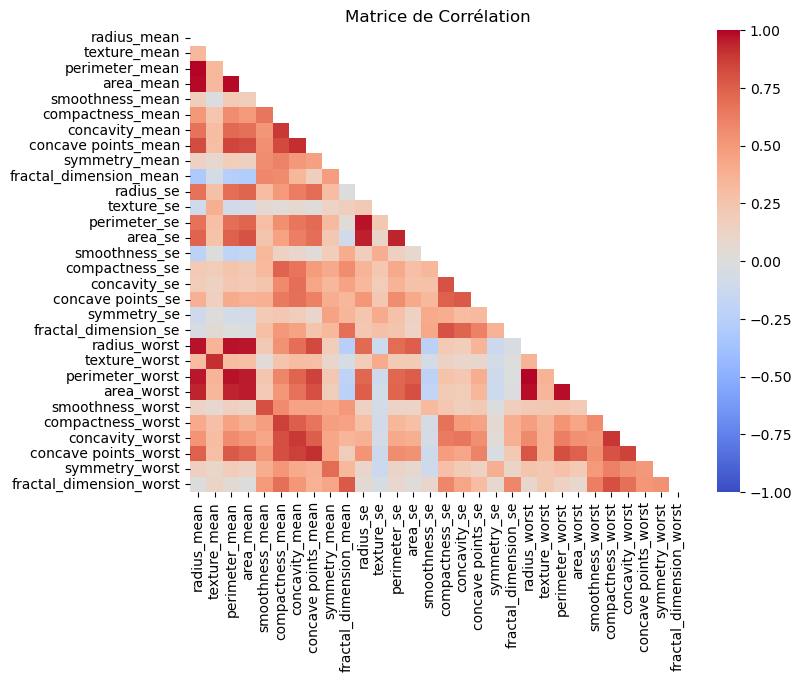

In [31]:
corr = df[colonnes_continues].corr()

# 2. Affichage du graphique sans annotations
plt.figure(figsize=(8, 6))
sns.heatmap(corr, mask=np.triu(np.ones_like(corr, dtype=bool)), 
            cmap='coolwarm', vmin=-1, vmax=1, annot=False)
plt.title("Matrice de Corrélation")
plt.show()

### Corrélations et Multicolinéarité

**1. Corrélation avec le diagnostic**
Les mesures liées aux points concaves, au périmètre et à la surface (en particulier les métriques `worst` et `mean`) sont les prédicteurs les plus forts de la malignité (corrélations > 0.7). À l'inverse, cinq variables (`fractal_dimension_se`, `symmetry_se`, `texture_se`, `fractal_dimension_mean`, `smoothness_se`) présentent une corrélation proche de zéro. Elles n'aident pas à la décision et doivent être supprimées pour éliminer le bruit.

**2. Multicolinéarité et Redondance**
Il existe une redondance mathématique critique (corrélation > 0.9) entre plusieurs variables décrivant la même réalité biologique. Pour éviter de fausser les pondérations du Perceptron, seule la variable la plus prédictive de chaque groupe colinéaire est conservée, tandis que ses doublons sont éliminés. Les 4 groupes redondants identifiés sont :
* **Taille et Géométrie :** `radius_mean`, `perimeter_mean`, `area_mean`, `radius_worst`, `perimeter_worst`, `area_worst`
* **Erreur Standard de Géométrie :** `radius_se`, `perimeter_se`, `area_se`
* **Points Concaves et Concavité :** `concavity_mean`, `concave points_mean`, `concave points_worst`
* **Texture :** `texture_mean`, `texture_worst`

**3. Variables conservées (Sélection finale)**
Après élimination du bruit et des variables colinéaires, nous conservons les 15 variables explicatives les plus pertinentes et décorrélées pour entraîner le Perceptron :
`perimeter_worst`, `radius_se`, `concave points_worst`, `texture_worst`, `smoothness_mean`, `compactness_mean`, `symmetry_mean`, `compactness_se`, `concavity_se`, `concave points_se`, `smoothness_worst`, `compactness_worst`, `concavity_worst`, `symmetry_worst`, `fractal_dimension_worst`.

## Standardisation 

In [24]:
# On isole les colonnes continues
X = df[colonnes_continues]

#Application du RobustScaler
scaler = RobustScaler()
X_scaled = scaler.fit_transform(X)

# Mise à jour du df avec valeurs transformé
df[colonnes_continues] = X_scaled
df

,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,...,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst,Unnamed: 32
0,842302,M,1.132353,-1.502664,1.263740,1.241446,1.190174,2.824832,2.358711,2.115850,...,-0.935185,2.105595,2.343063,1.051020,2.364252,1.807750,1.715248,2.635556,1.884578,NaN
1,842517,M,1.764706,-0.190053,1.612859,2.138245,-0.587956,-0.213653,0.250742,0.682995,...,-0.231481,1.480746,2.232284,-0.255102,-0.131839,0.055514,0.892194,-0.106667,0.435500,NaN
2,84300903,M,1.549020,0.428064,1.512617,1.798841,0.725304,1.027337,1.343287,1.758242,...,0.013889,1.328167,1.797960,0.445578,1.107869,0.833458,1.483052,1.171852,0.365664,NaN
3,84348301,M,-0.477941,0.273535,-0.299343,-0.455298,2.463286,2.921045,1.778327,1.335444,...,0.126157,0.029305,-0.208897,2.670068,3.410109,1.714605,1.633358,5.653333,4.508244,NaN
4,84358402,M,1.696078,-0.799290,1.688904,2.058223,0.234020,0.613470,1.349219,1.318681,...,-1.011574,1.320901,1.562335,0.207483,-0.035956,0.645678,0.648595,-0.678519,-0.158099,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
564,926424,M,2.007353,0.630551,1.927411,2.560430,0.799260,0.355376,1.803045,1.963122,...,0.114583,1.657544,2.357130,0.329932,-0.003127,0.685544,1.261221,-1.128889,-0.431135,NaN
565,926682,M,1.656863,1.671403,1.554096,1.958885,0.101955,0.164478,0.815306,1.199665,...,1.486111,1.388714,1.836645,-0.500000,-0.102658,0.353204,0.651705,-0.370370,-0.662949,NaN
566,926954,M,0.791667,1.641208,0.762530,0.847130,-0.597993,0.147679,0.306209,0.363569,...,1.008102,0.703318,0.769298,-0.591837,0.508077,0.423249,0.434021,-0.894815,-0.089234,NaN
567,927241,M,1.772059,1.863233,1.861735,1.969923,1.158479,2.815669,2.865928,2.207115,...,1.621528,2.105595,1.994901,1.146259,3.419489,2.652757,1.711102,1.874074,2.131911,NaN
